<a href="https://colab.research.google.com/github/thientuwl/PROJECT_INTRO-TO-DATA-SCIENCE/blob/main/D2_Topic02_Group_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IT135IU – D2: Data and Profiling
**Topic 2 – Where should the city add an air-quality monitoring station? (Seoul, 2022 hourly data)**

| Student ID | Name | Role |
|---|---|---|
|ITDSIU25003| Lưu Ngọc Quỳnh Anh | Product owner |
| ITDSIU25052 |Nguyễn Vinh | Data engineer |
| ITDSIU25023| Nguyễn Thị Kim Ngân | Data analyst |
| ITDSIU25046 | Dương Ngọc Bảo Thy | Visualisation lead |
| ITDSIU25050 | Nguyễn Hoàng Thiên Tứ | Reproducibility lead |
| ITDSIU25045 |Trần Lê Ngọc Thủy | Ethics and privacy officer |

**Contents:** 1 Data source · 2 Load data · 3 Data profile · 4 Cleaning log · 5 Data manipulation operations (5) · 6 Potential bias (Historical / Representation) · 7 Reproducibility notes

## 1. Data source record  

**Working file:** `seoul_air_quality_2022_english.csv` – 216,545 rows × 17 columns (meets the ≥ 50,000-row requirement). It is a processed merge of three open datasets from the Seoul Metropolitan Government (Seoul Open Data Plaza), joined on district and year. Merge prepared by: Data Engineer
| | (a) Air pollution | (b) Registered households and population | (c) Population density by district |
|---|---|---|---|
| Dataset | 서울시 대기오염 측정정보 (OA-15526), file `AIR_HOUR_2022.csv`, last updated 2023-04-03 | Registered Households and Population (updated quarterly) | Population Density by District (updated annually) |
| Publisher | Seoul Metropolitan Government Research Institute of Public Health and Environment (서울특별시 보건환경연구원), via Seoul Open Data Plaza | Data Strategy Division, Digital City Bureau, Seoul Metropolitan Government | Same division as (b) |
| URL | https://data.seoul.go.kr/dataList/OA-15526/A/1/datasetView.do | https://data.seoul.go.kr/bsp/wgs/dataView/data300View/109.do | https://data.seoul.go.kr/bsp/wgs/dataView/data300View/37.do |
| Date of retrieval | 21/09/2026 | 21/09/2026 | 21/09/2026 |
| Terms of use | KOGL Type 1 (Gonggongnuri Type 1): commercial use and modification permitted, attribution required.| Same  | Same |
| Reference period | Hourly, 1 Jan – 31 Dec 2022 | Hourly, 1 Jan – 31 Dec 2022  | Hourly, 1 Jan – 31 Dec 2022 |

* **Content:** hourly CO, NO2, O3, SO2 (ppm) and PM10, PM2.5 (µg/m³) at 25 stations (one per district / *gu*), combined with district population, households, male/female counts, area (km²) and population density.
* **Personal data:** none. All three datasets are aggregated at district level; no names, addresses or household-level records.
* **Data status:** the publisher states that the air-quality data is *not the final confirmed version* (final data: AirKorea). The original file also carries instrument-status and exceedance columns that are absent from the working file
* **Attribution:** Contains data Seoul Metropolitan Government, used under KOGL Type 1.

## 2. Load data

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

SEED = 42                      # no random operation is used in D2; fixed anyway for D3 (sampling / modelling)
np.random.seed(SEED)

df_raw = pd.read_csv('seoul_air_quality_2022_english.csv')
df = df_raw.copy()
print(df_raw.shape)
df_raw.head(10)

(216545, 17)


,datetime,station_code,district,CO,NO2,O3,PM10,PM2.5,SO2,population,area_km2,population_density,households,male_population,female_population,district_code,year
0,1/1/2022 0:00,101,Jongno-gu,0.4,0.016,0.026,23.0,12.0,0.003,152211,23.91,6365,72524,72980,79231,1111000000,2022
1,1/1/2022 0:00,102,Jung-gu,0.4,0.024,0.016,25.0,10.0,0.003,130785,9.96,13131,63139,63377,67408,1114000000,2022
2,1/1/2022 0:00,103,Yongsan-gu,0.4,0.020,0.020,24.0,13.0,0.003,233284,21.87,10668,109805,113012,120272,1117000000,2022
3,1/1/2022 0:00,104,Eunpyeong-gu,0.8,0.019,0.019,19.0,10.0,0.004,470602,29.71,15838,213876,224163,246439,1138000000,2022
4,1/1/2022 0:00,105,Seodaemun-gu,0.7,0.020,0.019,23.0,13.0,NaN,319554,17.63,18129,145797,150094,169460,1141000000,2022
5,1/1/2022 0:00,106,Mapo-gu,0.4,0.026,0.014,18.0,6.0,0.002,375585,23.85,15745,180084,175006,200579,1144000000,2022
6,1/1/2022 0:00,107,Seongdong-gu,0.3,0.017,0.024,19.0,5.0,0.003,288234,16.82,17136,133305,139691,148543,1120000000,2022
7,1/1/2022 0:00,108,Gwangjin-gu,0.7,0.025,0.018,17.0,8.0,0.001,351252,17.06,20586,169291,168197,183055,1121500000,2022
8,1/1/2022 0:00,109,Dongdaemun-gu,0.4,0.021,0.022,16.0,11.0,0.002,353601,14.22,24873,169873,171903,181698,1123000000,2022
9,1/1/2022 0:00,110,Jungnang-gu,0.4,0.019,0.025,21.0,8.0,0.003,390140,18.50,21092,187413,191422,198718,1126000000,2022


## 3. Data profile

In [4]:
profile = pd.DataFrame({
    'Data type':   df_raw.dtypes.astype(str),
    'Non-null':    df_raw.notnull().sum(),
    'Missing':     df_raw.isnull().sum(),
    'Missing %':   (df_raw.isnull().mean()*100).round(3),
    'Unique':      df_raw.nunique(),
    'Min':         df_raw.min(numeric_only=False),
    'Max':         df_raw.max(numeric_only=False),
})
# 'datetime' is text in the raw file, so min/max would be sorted alphabetically (e.g. '9/9/2022'): use parsed values
_dt = pd.to_datetime(df_raw['datetime'], format='%m/%d/%Y %H:%M')
profile.loc['datetime', ['Min','Max']] = [str(_dt.min()), str(_dt.max())]
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(profile)

Rows: 216,545 | Columns: 17


,Data type,Non-null,Missing,Missing %,Unique,Min,Max
datetime,object,216545,0,0.000,8760,2022-01-01 00:00:00,2022-12-31 23:00:00
station_code,int64,216545,0,0.000,25,101,125
district,object,216545,0,0.000,25,Dobong-gu,Yongsan-gu
CO,float64,215142,1403,0.648,20,0.1,2.0
NO2,float64,215540,1005,0.464,93,0.001,0.096
O3,float64,215209,1336,0.617,154,0.0,0.167
PM10,float64,214136,2409,1.112,359,1.0,482.0
PM2.5,float64,214805,1740,0.804,124,1.0,126.0
SO2,float64,214839,1706,0.788,15,0.001,0.016
population,int64,216545,0,0.000,25,130785,664514


In [5]:
# Structural checks (computed, not assumed)
df['datetime'] = pd.to_datetime(df['datetime'], format='%m/%d/%Y %H:%M')
print('Period:', df['datetime'].min(), '->', df['datetime'].max())
print('Duplicate (district, datetime):', df.duplicated(['district','datetime']).sum())
print('Fully duplicated rows:         ', df.duplicated().sum())
print('Stations per district (max):   ', df.groupby('district')['station_code'].nunique().max())
print('Demographic columns constant within district:',
      (df.groupby('district')[['population','area_km2','population_density','households']].nunique()==1).all().all())
print('male + female == population:   ', (df.male_population+df.female_population==df.population).all())
print("'year' column constant (=2022):", df['year'].nunique()==1)
display(df.describe().T.round(4))

Period: 2022-01-01 00:00:00 -> 2022-12-31 23:00:00
Duplicate (district, datetime): 0
Fully duplicated rows:          0
Stations per district (max):    1
Demographic columns constant within district: True
male + female == population:    True
'year' column constant (=2022): True


,count,mean,min,25%,50%,75%,max,std
datetime,216545,2022-07-02 08:35:06.717772032,2022-01-01 00:00:00,2022-04-01 20:00:00,2022-07-01 22:00:00,2022-10-02 02:00:00,2022-12-31 23:00:00,NaN
station_code,216545.0,113.006812,101.0,107.0,113.0,119.0,125.0,7.214851
CO,215142.0,0.43707,0.1,0.3,0.4,0.5,2.0,0.185666
NO2,215540.0,0.020868,0.001,0.011,0.017,0.028,0.096,0.013388
O3,215209.0,0.029275,0.0,0.015,0.027,0.04,0.167,0.019398
PM10,214136.0,32.861625,1.0,19.0,28.0,41.0,482.0,22.842114
PM2.5,214805.0,18.378618,1.0,9.0,15.0,24.0,126.0,13.907109
SO2,214839.0,0.002886,0.001,0.002,0.003,0.003,0.016,0.000843
population,216545.0,386814.131368,130785.0,313989.0,390432.0,464037.0,664514.0,122930.793712
area_km2,216545.0,24.237395,9.96,17.41,23.6,29.57,46.97,9.121672


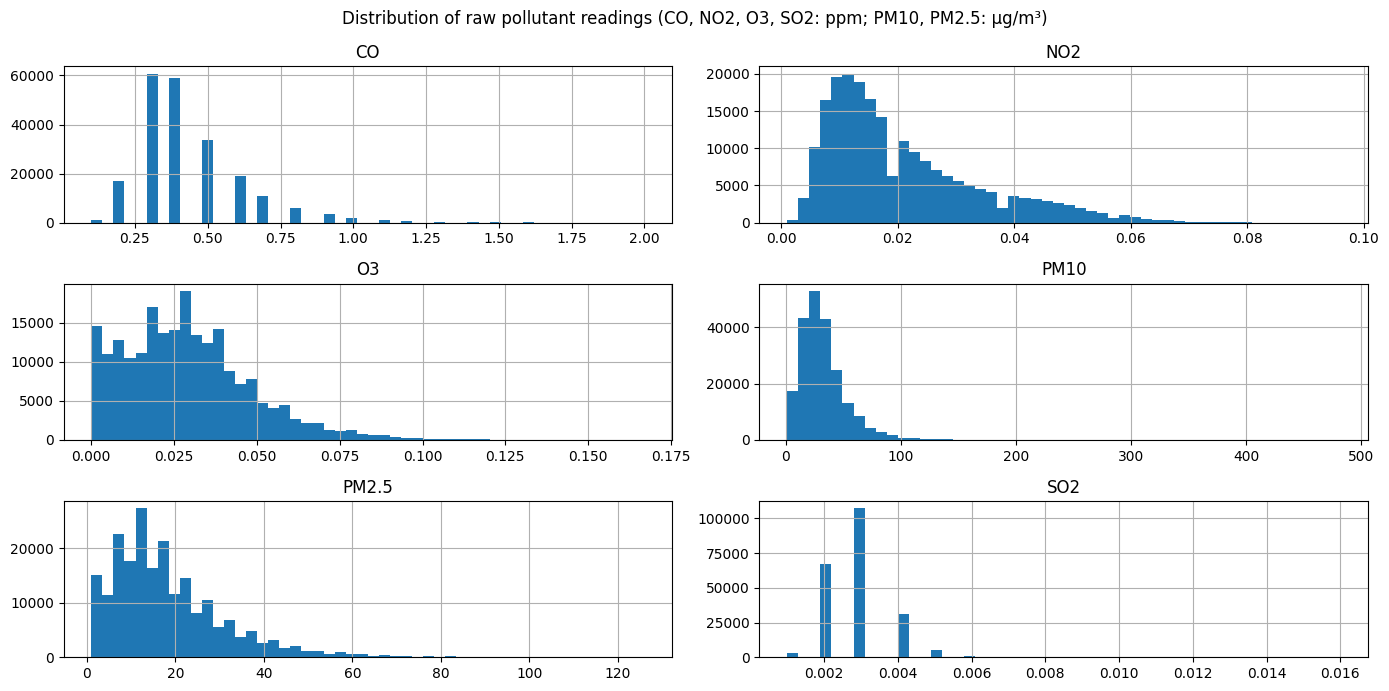

In [6]:
df[['CO','NO2','O3','PM10','PM2.5','SO2']].hist(bins=50, figsize=(14,7))
plt.suptitle('Distribution of raw pollutant readings (CO, NO2, O3, SO2: ppm; PM10, PM2.5: µg/m³)')
plt.tight_layout(); plt.show()

### 3.1 Missing timestamps (rows absent from the file)
A complete record would have 25 stations × 8,760 hours = 219,000 rows; the file has 216,545, so **2,455 station-hours are absent**.

Expected: 219000 | Present: 216545 | Absent: 2455


,district,gap_id,start,end,hours
34,Dongdaemun-gu,35,2022-08-08 18:00:00,2022-08-31 16:00:00,551
279,Gwanak-gu,280,2022-11-11 17:00:00,2022-11-14 17:00:00,73
214,Geumcheon-gu,215,2022-04-02 05:00:00,2022-04-04 11:00:00,55
526,Songpa-gu,527,2022-07-22 17:00:00,2022-07-24 12:00:00,44
223,Geumcheon-gu,224,2022-08-02 11:00:00,2022-08-03 16:00:00,30


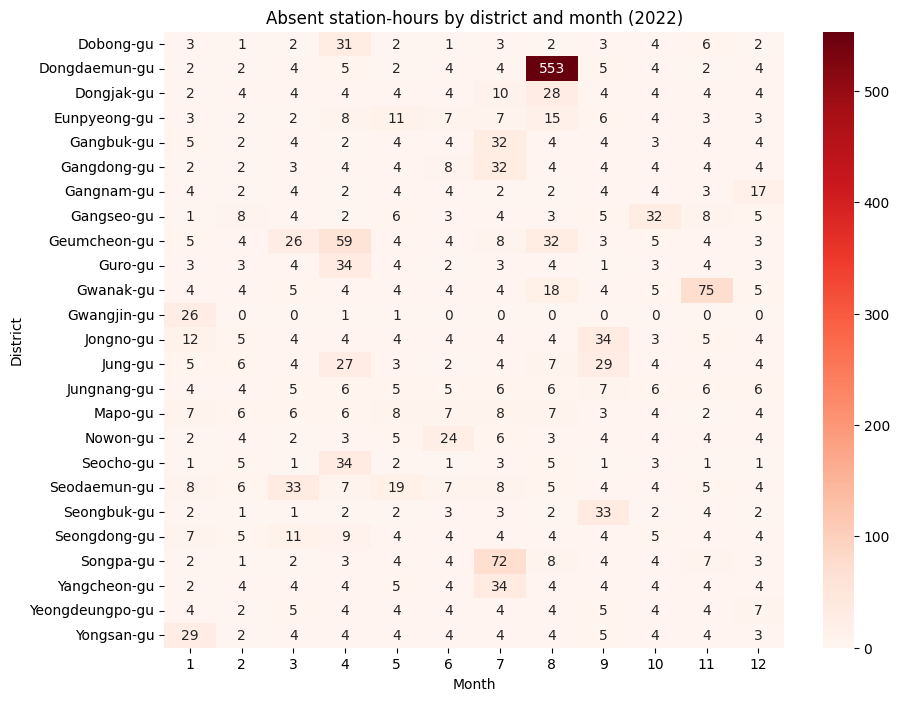

In [7]:
full_idx = pd.date_range('2022-01-01 00:00', '2022-12-31 23:00', freq='h')
expected = pd.MultiIndex.from_product([sorted(df['district'].unique()), full_idx], names=['district','datetime'])
present  = pd.MultiIndex.from_frame(df[['district','datetime']])
missing_rows = expected.difference(present).to_frame(index=False)
print('Expected:', len(expected), '| Present:', len(df), '| Absent:', len(missing_rows))

missing_rows['month'] = missing_rows['datetime'].dt.month
gap_id = (missing_rows.sort_values(['district','datetime']).groupby('district')['datetime'].diff() != pd.Timedelta(hours=1)).cumsum()
gaps = (missing_rows.sort_values(['district','datetime']).assign(gap_id=gap_id)
        .groupby(['district','gap_id']).agg(start=('datetime','min'), end=('datetime','max'), hours=('datetime','size'))
        .reset_index().sort_values('hours', ascending=False))
display(gaps.head(5))

pivot = missing_rows.pivot_table(index='district', columns='month', values='datetime', aggfunc='size', fill_value=0)
plt.figure(figsize=(10,8)); sns.heatmap(pivot, annot=True, fmt='d', cmap='Reds')
plt.title('Absent station-hours by district and month (2022)'); plt.xlabel('Month'); plt.ylabel('District'); plt.show()

## 4. Cleaning log

In [8]:
cleaning_log = []
def log_action(step, issue, action, reason, n=None):
    cleaning_log.append({'Step': step, 'Issue': issue, 'Action': action, 'Reason': reason, 'Rows / cells affected': n})

pollutants = ['CO','NO2','O3','PM10','PM2.5','SO2']

# --- Step 1-2: datetime + time features
df['hour']   = df['datetime'].dt.hour
df['month']  = df['datetime'].dt.month
df['date']   = df['datetime'].dt.date
def get_season(m):
    return 'Winter' if m in (12,1,2) else 'Spring' if m in (3,4,5) else 'Summer' if m in (6,7,8) else 'Autumn'
df['season'] = df['month'].apply(get_season)
log_action(1, 'datetime stored as text (M/D/YYYY H:mm)', 'Parsed with explicit format', 'Needed for hourly / daily / seasonal analysis', len(df))
log_action(2, 'No time features', 'Created hour, month, date, season', 'Needed for grouped imputation and daily aggregation', len(df))

# --- Step 3: duplicates
n_dup = int(df.duplicated(['district','datetime']).sum())
log_action(3, 'Possible duplicate (district, datetime)', f'Checked: {n_dup} found', 'No removal needed', n_dup)

# --- Step 4: missing pollutant values -> group median
miss_before = df[pollutants].isnull().sum()
for p in pollutants:
    df[p] = df[p].fillna(df.groupby(['station_code','hour','season'])[p].transform('median'))
miss_after = df[pollutants].isnull().sum()
imputed_cells = int(miss_before.sum() - miss_after.sum())
log_action(4, f'Missing pollutant readings ({int(miss_before.sum()):,} cells, {miss_before.sum()/(len(df)*6)*100:.2f}% of all pollutant cells)',
           'Median imputation within (station, hour-of-day, season)',
           'Low missing rate; deleting rows would break the hourly series. Median chosen because readings are right-skewed (mean > median)',
           imputed_cells)
log_action(5, f'{25*8760-len(df_raw):,} station-hours absent from the file (Dongdaemun-gu: 551 consecutive hours, 8-31 Aug)',
           'Reported, NOT imputed', 'Avoid inventing data; daily means for these days use fewer hours', 25*8760-len(df_raw))

# --- Step 6: units (new columns, originals kept)
FACTORS = {'NO2':1880, 'SO2':2620, 'O3':1960, 'CO':1145}     # ug/m3 per ppm at 25 C, 1 atm
for g, f in FACTORS.items():
    df[f'{g}_ugm3'] = df[g]*f
log_action(6, 'Mixed units: gases in ppm, PM in µg/m³', 'Converted gases to µg/m³ in NEW columns (NO2_ugm3, SO2_ugm3, O3_ugm3, CO_ugm3)',
           'Compare with WHO guidelines (µg/m³); assumes 25 °C and 1 atm; raw columns kept', len(df))

# --- Step 7: outliers
x = df.loc[df['PM10'].idxmax()]
same_hour = df[df['datetime']==x['datetime']]['PM10']
log_action(7, f'Extreme PM10 = {x.PM10:.0f} µg/m³ ({x.district}, {x.datetime})',
           'Kept as is', f'Same hour: median of 25 stations = {same_hour.median():.0f}, so it is a city-wide episode, not a sensor error', 1)

# --- Step 8-9: daily aggregation and WHO flags (done in section 5)
log_action(8, 'Hourly data too granular for 24-h guideline', 'Aggregate to daily mean per district (section 5, op. 3)', 'WHO guidelines are 24-hour means')
log_action(9, 'No definition of a "polluted" day', 'Flag day if daily mean exceeds WHO 2021 24-h guideline: PM2.5 > 15, PM10 > 45, NO2 > 25 µg/m³ (section 5, op. 2)',
           'Guidelines are health benchmarks, not legal limits')

# --- Step 10-11: structural findings
log_action(10, "Constant / redundant columns: 'year' (always 2022); 'station_code' and 'district_code' 1:1 with district", 'Kept, not used in analysis', 'No information gain; kept for traceability')
log_action(11, 'Low-resolution SO2 (values only 0.001-0.016 ppm in 0.001 steps)', 'Kept; SO2 not used for ranking', 'Rounding to 3 decimals makes SO2 too coarse to separate districts')

log_df = pd.DataFrame(cleaning_log).fillna('—')
pd.set_option('display.max_colwidth', 140)
display(log_df)
print('Remaining missing after cleaning:\n', df[pollutants].isnull().sum().to_string())

,Step,Issue,Action,Reason,Rows / cells affected
0,1,datetime stored as text (M/D/YYYY H:mm),Parsed with explicit format,Needed for hourly / daily / seasonal analysis,216545.0
1,2,No time features,"Created hour, month, date, season",Needed for grouped imputation and daily aggregation,216545.0
2,3,"Possible duplicate (district, datetime)",Checked: 0 found,No removal needed,0.0
3,4,"Missing pollutant readings (9,599 cells, 0.74% of all pollutant cells)","Median imputation within (station, hour-of-day, season)",Low missing rate; deleting rows would break the hourly series. Median chosen because readings are right-skewed (mean > median),9599.0
4,5,"2,455 station-hours absent from the file (Dongdaemun-gu: 551 consecutive hours, 8-31 Aug)","Reported, NOT imputed",Avoid inventing data; daily means for these days use fewer hours,2455.0
5,6,"Mixed units: gases in ppm, PM in µg/m³","Converted gases to µg/m³ in NEW columns (NO2_ugm3, SO2_ugm3, O3_ugm3, CO_ugm3)",Compare with WHO guidelines (µg/m³); assumes 25 °C and 1 atm; raw columns kept,216545.0
6,7,"Extreme PM10 = 482 µg/m³ (Gangbuk-gu, 2022-12-13 10:00:00)",Kept as is,"Same hour: median of 25 stations = 353, so it is a city-wide episode, not a sensor error",1.0
7,8,Hourly data too granular for 24-h guideline,"Aggregate to daily mean per district (section 5, op. 3)",WHO guidelines are 24-hour means,—
8,9,"No definition of a ""polluted"" day","Flag day if daily mean exceeds WHO 2021 24-h guideline: PM2.5 > 15, PM10 > 45, NO2 > 25 µg/m³ (section 5, op. 2)","Guidelines are health benchmarks, not legal limits",—
9,10,Constant / redundant columns: 'year' (always 2022); 'station_code' and 'district_code' 1:1 with district,"Kept, not used in analysis",No information gain; kept for traceability,—


Remaining missing after cleaning:
 CO       0
NO2      0
O3       0
PM10     0
PM2.5    0
SO2      0


In [9]:
# Imputation share per district and column (feeds the bias discussion, section 6)
imp_share = (df_raw.assign(district=df_raw['district'])[pollutants].isnull().groupby(df_raw['district']).mean()*100).round(2)
display(imp_share.sort_values('SO2', ascending=False).head(5))

,CO,NO2,O3,PM10,PM2.5,SO2
district,,,,,,
Yangcheon-gu,0.06,0.54,1.28,0.76,0.83,7.72
Seodaemun-gu,2.43,1.19,1.64,0.81,0.38,4.51
Seongdong-gu,0.38,0.45,0.40,0.40,0.30,2.12
Dongjak-gu,0.02,0.02,0.05,0.97,0.47,1.21
Gwangjin-gu,1.07,0.74,0.74,0.68,0.68,0.71


## 5. Data manipulation operations
Five operations: (1) filtering, (2) derived columns, (3) grouping and aggregation, (4) a second grouping on the derived flags, (5) merging two tables.

### Operation 1 – Filtering: extreme-pollution hours (PM2.5 > 75 µg/m³, WHO interim target 1)

In [10]:
high = df[df['PM2.5'] > 75]
print(f'{len(high):,} of {len(df):,} station-hours ({len(high)/len(df)*100:.2f}%)')
display(high.groupby('month').size().rename('station-hours with PM2.5 > 75').to_frame().T)

1,480 of 216,545 station-hours (0.68%)


month,1,2,3,4,5,9,10,11
station-hours with PM2.5 > 75,869,448,39,13,1,26,1,83


### Operation 2 – Derived columns: daily guideline-exceedance flags

In [11]:
daily = (df.groupby(['district','date'])
           .agg(PM25_mean=('PM2.5','mean'), PM10_mean=('PM10','mean'), NO2_mean=('NO2_ugm3','mean'),
                hours=('datetime','size'))
           .reset_index())
daily['PM25_exceed'] = daily['PM25_mean'] > 15
daily['PM10_exceed'] = daily['PM10_mean'] > 45
daily['NO2_exceed']  = daily['NO2_mean']  > 25
daily['any_exceed']  = daily[['PM25_exceed','PM10_exceed','NO2_exceed']].any(axis=1)
print('District-days:', len(daily), '| days with < 18 hourly readings:', int((daily['hours']<18).sum()))
display(daily.head())
display(daily[['PM25_exceed','PM10_exceed','NO2_exceed','any_exceed']].mean().mul(100).round(1).rename('% of district-days exceeding').to_frame())

District-days: 9099 | days with < 18 hourly readings: 47


,district,date,PM25_mean,PM10_mean,NO2_mean,hours,PM25_exceed,PM10_exceed,NO2_exceed,any_exceed
0,Dobong-gu,2022-01-01,16.833333,33.041667,66.818333,24,True,False,True,True
1,Dobong-gu,2022-01-02,23.125000,34.000000,46.216667,24,True,False,True,True
2,Dobong-gu,2022-01-03,14.750000,25.375000,62.980000,24,False,False,True,True
3,Dobong-gu,2022-01-04,19.333333,34.791667,29.218333,24,True,False,True,True
4,Dobong-gu,2022-01-05,30.208333,52.333333,63.136667,24,True,True,True,True


,% of district-days exceeding
PM25_exceed,52.9
PM10_exceed,18.7
NO2_exceed,71.3
any_exceed,78.6


### Operation 3 – Grouping and aggregation: typical daily level per district

In [12]:
district_typical = (daily.groupby('district')
                      .agg(PM25_median=('PM25_mean','median'), PM10_median=('PM10_mean','median'), NO2_median=('NO2_mean','median'))
                      .round(1).sort_values('PM25_median', ascending=False))
display(district_typical)
print('Spread of district-level PM2.5 medians:', district_typical['PM25_median'].min(), '-', district_typical['PM25_median'].max())

,PM25_median,PM10_median,NO2_median
district,,,
Nowon-gu,17.8,29.4,32.1
Dongjak-gu,17.4,30.8,32.7
Yangcheon-gu,17.2,30.1,33.1
Eunpyeong-gu,17.0,27.4,27.9
Yongsan-gu,16.8,29.5,36.5
Jongno-gu,16.6,28.1,33.4
Dongdaemun-gu,16.5,29.8,34.7
Gangdong-gu,16.2,29.8,33.0
Jung-gu,16.1,25.9,39.6


Spread of district-level PM2.5 medians: 13.0 - 17.8


### Operation 4 – Grouping: exceedance days per district, per guideline

In [13]:
exceed = (daily.groupby('district')[['PM25_exceed','PM10_exceed','NO2_exceed','any_exceed']].sum()
               .rename(columns=lambda c: c.replace('_exceed','')+'_days')
               .sort_values('any_days', ascending=False))
display(exceed)
print('Range of any_days:', exceed['any_days'].min(), '-', exceed['any_days'].max(), 'of ~365 days')

,PM25_days,PM10_days,NO2_days,any_days
district,,,,
Jung-gu,206,54,307,323
Yeongdeungpo-gu,197,59,301,318
Gangnam-gu,187,61,307,318
Seongbuk-gu,182,79,304,313
Songpa-gu,201,67,296,311
Mapo-gu,182,51,301,310
Gwanak-gu,194,71,291,309
Dongjak-gu,230,81,265,304
Yongsan-gu,216,67,276,304


Range of any_days: 220 - 323 of ~365 days


### Operation 5 – Merging two tables
The CSV already carries demographics on every hourly row. To make the merge explicit, the 25-row **district demographics table** is separated from the hourly data and **merged back** onto the exceedance table (left join on `district`, validated one-to-one).

In [14]:
demo = (df_raw[['district','population','area_km2','population_density','households']]
          .drop_duplicates().reset_index(drop=True))
print('Demographics table:', demo.shape, '| one row per district:', demo['district'].is_unique)

district_table = exceed.reset_index().merge(demo, on='district', how='left', validate='one_to_one')
assert district_table[['population','area_km2']].notnull().all().all() and len(district_table)==25
district_table['pop_per_station'] = district_table['population']          # 1 station per district
district_table['km2_per_station'] = district_table['area_km2']
display(district_table)

Demographics table: (25, 5) | one row per district: True


,district,PM25_days,PM10_days,NO2_days,any_days,population,area_km2,population_density,households,pop_per_station,km2_per_station
0,Jung-gu,206,54,307,323,130785,9.96,13131,63139,130785,9.96
1,Yeongdeungpo-gu,197,59,301,318,398085,24.55,16215,188832,398085,24.55
2,Gangnam-gu,187,61,307,318,534103,39.50,13522,232777,534103,39.50
3,Seongbuk-gu,182,79,304,313,441984,24.58,17983,197082,441984,24.58
4,Songpa-gu,201,67,296,311,664514,33.88,19616,284853,664514,33.88
5,Mapo-gu,182,51,301,310,375585,23.85,15745,180084,375585,23.85
6,Gwanak-gu,194,71,291,309,501226,29.57,16951,283623,501226,29.57
7,Dongjak-gu,230,81,265,304,390432,16.36,23870,185773,390432,16.36
8,Yongsan-gu,216,67,276,304,233284,21.87,10668,109805,233284,21.87
9,Geumcheon-gu,194,60,289,302,242818,13.02,18649,119583,242818,13.02


## 6. Potential bias in the data *(Ethics and privacy officer)*
Computed evidence first, interpretation below each table. These notes feed Section 6 of the final report.

### 6.1 Representation bias – who / what is (under-)represented

In [15]:
cov = district_table[['district','population','area_km2','population_density','any_days']].copy()
cov['stations'] = 1
print(f"Residents per station: {cov['population'].min():,} - {cov['population'].max():,}  (x{cov['population'].max()/cov['population'].min():.1f})")
print(f"Area per station:      {cov['area_km2'].min():.1f} - {cov['area_km2'].max():.1f} km2  (x{cov['area_km2'].max()/cov['area_km2'].min():.1f})")

miss_by_d = (missing_rows.groupby('district').size().reindex(sorted(df['district'].unique()), fill_value=0)
             .rename('absent hours').to_frame())
miss_by_d['% of 8,760'] = (miss_by_d['absent hours']/8760*100).round(2)
display(miss_by_d.sort_values('absent hours', ascending=False).head(6))
print('Absent hours in August overall:', int((missing_rows['month']==8).sum()), 'of', len(missing_rows),
      f"({(missing_rows['month']==8).mean()*100:.0f}%); Dongdaemun-gu alone: {int(((missing_rows['month']==8)&(missing_rows['district']=='Dongdaemun-gu')).sum())}")

spread = daily.groupby('district')['PM25_mean'].mean()
print(f'Annual mean PM2.5 across districts: {spread.mean():.1f} µg/m3, SD between districts = {spread.std():.2f}, range {spread.min():.1f}-{spread.max():.1f}')
print('Missing-value cells imputed:', imputed_cells, f'({imputed_cells/(len(df)*6)*100:.2f}% of pollutant cells)')

Residents per station: 130,785 - 664,514  (x5.1)
Area per station:      10.0 - 47.0 km2  (x4.7)


,absent hours,"% of 8,760"
district,,
Dongdaemun-gu,591,6.75
Geumcheon-gu,157,1.79
Gwanak-gu,136,1.55
Songpa-gu,114,1.30
Seodaemun-gu,110,1.26
Jung-gu,99,1.13


Absent hours in August overall: 728 of 2455 (30%); Dongdaemun-gu alone: 553
Annual mean PM2.5 across districts: 18.3 µg/m3, SD between districts = 1.12, range 16.3-20.4
Missing-value cells imputed: 9599 (0.74% of pollutant cells)


**Findings – representation bias**
1. **One fixed station per district, whatever its size.** Each district has exactly one station, but a district holds 130,785–664,514 residents (≈ 5×) and covers 9.96–46.97 km² (≈ 4.7×). A large district is therefore described by one point; a small one by one point too. Hot spots *inside* a district (roadsides, industrial or airport areas) are invisible.
2. **Only places that already have a station are represented.** The data cannot say anything about the unmonitored parts of a district, so it cannot by itself show *where* a new station is needed – it can only rank the existing districts.
3. **Uneven time coverage.** Dongdaemun-gu has 591 absent hours (6.8% of its year, 24% of all absent hours in the file), of which 551 are one continuous outage (8–31 Aug 2022). Its summer is under-represented and its annual numbers are less comparable with the other 24 districts.
4. **Imputation under-represents extremes.** Median filling pulls imputed values to typical levels (small effect here: ≈ 0.7% of cells, but concentrated in a few stations, e.g. SO2 at Yangcheon-gu ≈ 7.7%).
5. **District differences are small.** Mean PM2.5 differs by only ≈ 4 µg/m³ between the best and worst district (SD ≈ 1.1). Regional / transboundary episodes affect the whole city at once, so rankings between districts can be as much about station location and sensor differences as about real district differences.
6. **Residents are under-described.** The data has only total / male / female counts: no age (children, elderly), income, health status or foreign residents, so "population at risk" cannot be measured properly.
7. **Provisional source data.** The publisher labels the air-quality file as not final-confirmed. If rows with abnormal instrument status were dropped during preparation, the absent hours are *not random* (they cluster in maintenance / outage periods, e.g. Dongdaemun-gu in August) and the remaining data under-represents those periods.
8. **Transferability.** Seoul (dense, one regulatory regime, 25 homogeneous stations) is not Ho Chi Minh City; conclusions should be framed as a method demonstrated on Seoul, not as a finding about Vietnam.

### 6.2 Historical bias – the past that is baked into the data

In [16]:
jung = district_table.set_index('district').loc['Jung-gu']
print(f"Jung-gu: {int(jung['population']):,} residents (lowest of 25) but {int(jung['any_days'])} polluted days (highest of 25)")
print('Spearman: polluted days vs population density =',
      round(district_table[['any_days','population_density']].corr(method='spearman').iloc[0,1],2),
      '| vs population =', round(district_table[['any_days','population']].corr(method='spearman').iloc[0,1],2))
print('Share of district-days "polluted" under the WHO-based rule:', round(daily['any_exceed'].mean()*100,1), '%',
      '(NO2 alone:', round(daily['NO2_exceed'].mean()*100,1), '%)')

Jung-gu: 130,785 residents (lowest of 25) but 323 polluted days (highest of 25)
Spearman: polluted days vs population density = -0.14 | vs population = 0.19
Share of district-days "polluted" under the WHO-based rule: 78.6 % (NO2 alone: 71.3 %)


**Findings – historical bias**
1. **Station placement is a historical decision.** The network (one station per *gu*, codes 101–125) follows administrative boundaries and past planning priorities, not an exposure-based design. The data therefore reflects where the city *chose to measure*; using it to decide where to measure next risks reproducing that earlier choice (circularity).
2. **2022 is one atypical year.** It is a single year (post-COVID reopening, one set of weather and long-range transport events, e.g. the city-wide PM10 episode on 13 Dec 2022). Rankings may change in other years; no trend can be inferred.
3. **Residential population ≠ people exposed.** Resident-registration counts and density (area includes mountains, rivers, parks) describe where people *live at night*. Districts with large daytime populations (e.g. Jung-gu has the fewest residents but the most polluted days) are under-weighted if density is used as the exposure proxy.
4. **Historical socio-economic differences are absent.** North/south differences in income, housing age and health vulnerability are long-standing in Seoul but are not in the data; a density-only criterion may direct resources to dense districts while missing vulnerable but less dense ones.
5. **The yardstick is a normative choice.** The WHO 2021 guideline is far stricter than Korea's national standards; with it, ≈ 79% of district-days count as "polluted" (≈ 71% from NO2 alone), so the metric barely separates districts (220–323 days). Another threshold would give a different ranking.

